In [221]:
!pip install yfinance

48749.55s - pydevd: Sending message related to process being replaced timed-out after 5 seconds



[notice] A new release of pip is available: 25.2 -> 25.3
[notice] To update, run: pip install --upgrade pip


In [222]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [223]:
pd.set_option('display.width', 160)
pd.set_option('display.max_columns',50)

plt.rcParams['figure.figsize'] = (10,5)

In [224]:
TICKERS = ['TSLA','NVDA', 'META', '^GSPC']
START = '2018-01-01'
END = None
INTERVAL = '1d'
print("tickers:", TICKERS, "start:", START, "end:", END, "interval:", INTERVAL)

tickers: ['TSLA', 'NVDA', 'META', '^GSPC'] start: 2018-01-01 end: None interval: 1d


In [225]:
df = yf.download(
    tickers = TICKERS,
    start = START,
    end = END,
    interval = INTERVAL,
    auto_adjust = True,
    group_by = 'ticker',
    progress = False,
    threads = True
)

df.index = pd.to_datetime(df.index).tz_localize(None)
print(type(df.columns), df.shape)
df.head()

<class 'pandas.core.indexes.multi.MultiIndex'> (1980, 20)


Ticker            ^GSPC                                                           META                                                    NVDA            \
Price              Open         High          Low        Close      Volume        Open        High         Low       Close    Volume      Open      High   
Date                                                                                                                                                       
2018-01-02  2683.729980  2695.889893  2682.360107  2695.810059  3397430000  176.591366  180.467480  176.462172  180.308456  18151900  4.840543  4.932518   
2018-01-03  2697.850098  2714.370117  2697.770020  2713.060059  3544030000  180.765644  183.647870  180.219011  183.538544  16886600  5.046248  5.283602   
2018-01-04  2719.310059  2729.290039  2719.070068  2723.989990  3697340000  183.767107  185.069093  182.972021  183.200607  13880900  5.334535  5.391154   
2018-01-05  2731.330078  2743.449951  2727.919922  2743.149902  3239280000  184.452895  185.754866  183.796935  185.705185  13574500  5.295717  5.362967   
2018-01-08  2742.669922  2748.510010  2737.600098  2747.709961  3246160000  186.053034  187.742616  185.188370  187.126419  17994700  5.449257  5.562989   

Ticker                                          TSLA                                              
Price            Low     Close     Volume       Open       High        Low      Close     Volume  
Date                                                                                              
2018-01-02  4.808896  4.928809  355616000  20.799999  21.474001  20.733334  21.368668   65283000  
2018-01-03  5.037594  5.253191  914704000  21.400000  21.683332  21.036667  21.150000   67822500  
2018-01-04  5.258631  5.280883  583268000  20.858000  21.236668  20.378668  20.974667  149194500  
2018-01-05  5.218824  5.325634  580124000  21.108000  21.149332  20.799999  21.105333   68868000  
2018-01-08  5.404258  5.488816  881216000  21.066668  22.468000  21.033333  22.427334  147891000

In [226]:
print("Data Set Shape:", df.shape)

Data Set Shape: (1980, 20)


In [227]:
print('Index range:', df.index.min(), "→", df.index.max(), "  rows:", len(df))

Index range: 2018-01-02 00:00:00 → 2025-11-14 00:00:00   rows: 1980


In [228]:
print("\nColumns preview:")
print(df.columns[:12])



Columns preview:
MultiIndex([('^GSPC',   'Open'),
            ('^GSPC',   'High'),
            ('^GSPC',    'Low'),
            ('^GSPC',  'Close'),
            ('^GSPC', 'Volume'),
            ( 'META',   'Open'),
            ( 'META',   'High'),
            ( 'META',    'Low'),
            ( 'META',  'Close'),
            ( 'META', 'Volume'),
            ( 'NVDA',   'Open'),
            ( 'NVDA',   'High')],
           names=['Ticker', 'Price'])


In [229]:
print("\n.info():")
df.info()



.info():
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1980 entries, 2018-01-02 to 2025-11-14
Data columns (total 20 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   (^GSPC, Open)    1980 non-null   float64
 1   (^GSPC, High)    1980 non-null   float64
 2   (^GSPC, Low)     1980 non-null   float64
 3   (^GSPC, Close)   1980 non-null   float64
 4   (^GSPC, Volume)  1980 non-null   int64  
 5   (META, Open)     1980 non-null   float64
 6   (META, High)     1980 non-null   float64
 7   (META, Low)      1980 non-null   float64
 8   (META, Close)    1980 non-null   float64
 9   (META, Volume)   1980 non-null   int64  
 10  (NVDA, Open)     1980 non-null   float64
 11  (NVDA, High)     1980 non-null   float64
 12  (NVDA, Low)      1980 non-null   float64
 13  (NVDA, Close)    1980 non-null   float64
 14  (NVDA, Volume)   1980 non-null   int64  
 15  (TSLA, Open)     1980 non-null   float64
 16  (TSLA, High)     1980 non-null  

In [230]:
if isinstance(df.columns, pd.MultiIndex):
    closes = df.xs("Close", level=1, axis=1)
else:
    closes = df["Close"].to_frame(TICKERS[0])

closes = closes.sort_index()
closes.head()

Ticker,^GSPC,META,NVDA,TSLA
Date,,,,
2018-01-02,2695.810059,180.308456,4.928809,21.368668
2018-01-03,2713.060059,183.538544,5.253191,21.150000
2018-01-04,2723.989990,183.200607,5.280883,20.974667
2018-01-05,2743.149902,185.705185,5.325634,21.105333
2018-01-08,2747.709961,187.126419,5.488816,22.427334


In [231]:
na_counts = closes.isna().sum()
print("NA per ticker:\n", na_counts)

# Forward-fill gaps, then drop any leading NAs that ffill couldn't fix
closes_ffill = closes.ffill().dropna(how="all")
print("After ffill → shape:", closes_ffill.shape)

closes_ffill.head()

NA per ticker:
 Ticker
^GSPC    0
META     0
NVDA     0
TSLA     0
dtype: int64
After ffill → shape: (1980, 4)


Ticker,^GSPC,META,NVDA,TSLA
Date,,,,
2018-01-02,2695.810059,180.308456,4.928809,21.368668
2018-01-03,2713.060059,183.538544,5.253191,21.150000
2018-01-04,2723.989990,183.200607,5.280883,20.974667
2018-01-05,2743.149902,185.705185,5.325634,21.105333
2018-01-08,2747.709961,187.126419,5.488816,22.427334


In [232]:
monthly_close = closes_ffill.resample("ME").last()
monthly_return = monthly_close.pct_change().dropna(how="all")
monthly_return = monthly_return * 100

print("monthly_close rows:", len(monthly_close), "  monthly_return rows:", len(monthly_return))
monthly_close.head()

monthly_close rows: 95   monthly_return rows: 94


Ticker,^GSPC,META,NVDA,TSLA
Date,,,,
2018-01-31,2823.810059,185.744934,6.077255,23.620667
2018-02-28,2713.830078,177.227448,5.987021,22.870667
2018-03-31,2640.870117,158.810944,5.729481,17.742001
2018-04-30,2648.050049,170.946182,5.563970,19.593332
2018-05-31,2705.270020,190.604980,6.242978,18.982000


In [233]:
monthly_return.head()

Ticker,^GSPC,META,NVDA,TSLA
Date,,,,
2018-02-28,-3.894737,-4.585582,-1.484787,-3.175186
2018-03-31,-2.688450,-10.391451,-4.301634,-22.424646
2018-04-30,0.271877,7.641311,-2.888771,10.434740
2018-05-31,2.160834,11.499993,12.203661,-3.120102
2018-06-30,0.484244,1.324430,-6.062881,20.447436


In [234]:
simple_returns = df.xs('Close', axis=1, level=1).pct_change()

window = 30
rolling_mean = simple_returns.rolling(window).mean()
rolling_vol = simple_returns.rolling(window).std() * np.sqrt(252)  # annualized vol (approx)

rolling_vol.tail()

Ticker,^GSPC,META,NVDA,TSLA
Date,,,,
2025-11-10,0.136906,0.409922,0.406841,0.532170
2025-11-11,0.136619,0.409443,0.411796,0.533482
2025-11-12,0.136400,0.411938,0.411787,0.527288
2025-11-13,0.145307,0.408662,0.424974,0.541513
2025-11-14,0.145319,0.405587,0.427516,0.540762


In [235]:
type(rolling_vol.META)

pandas.core.series.Series

In [236]:
type(rolling_vol)

pandas.core.frame.DataFrame

In [237]:
def compute_drawdown(price_series: pd.Series) -> pd.Series:
    cum_max = price_series.cummax()
    dd = price_series / cum_max - 1.0
    return dd

drawdowns = closes_ffill.apply(compute_drawdown)
drawdowns.tail()

Ticker,^GSPC,META,NVDA,TSLA
Date,,,,
2025-11-10,-0.008484,-0.199764,-0.038592,-0.072167
2025-11-11,-0.006426,-0.205692,-0.067040,-0.083858
2025-11-12,-0.005800,-0.228581,-0.063949,-0.102655
2025-11-13,-0.022261,-0.227466,-0.097469,-0.162276
2025-11-14,-0.022752,-0.228011,-0.081482,-0.157358


Max drawdown (fraction):
Ticker
META    -0.767361
TSLA    -0.736322
NVDA    -0.663351
^GSPC   -0.339250
dtype: float64

Occurred on:
Ticker
^GSPC   2020-03-23
META    2022-11-03
NVDA    2022-10-14
TSLA    2023-01-03
dtype: datetime64[ns]

Current drawdown:
Ticker
META    -0.228011
TSLA    -0.157358
NVDA    -0.081482
^GSPC   -0.022752
Name: 2025-11-14 00:00:00, dtype: float64


Text(0.5, 0, 'Year')

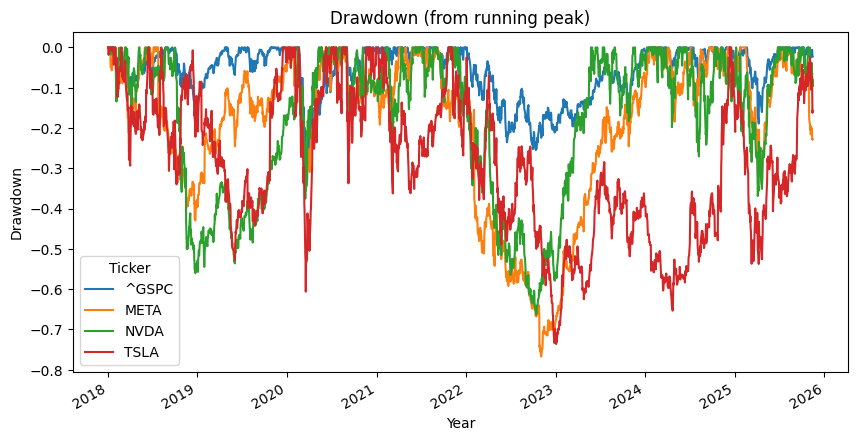

In [238]:
# Maximum drawdown (depth) per ticker and when it happened
max_dd = drawdowns.min()  # most negative value
dd_date = drawdowns.idxmin()

print("Max drawdown (fraction):")
print(max_dd.sort_values())
print("\nOccurred on:")
print(dd_date)

# Current drawdown (how far each is from its peak right now)
current_dd = drawdowns.iloc[-1]
print("\nCurrent drawdown:")
print(current_dd.sort_values())

ax = drawdowns.plot(title="Drawdown (from running peak)")
ax.set_ylabel("Drawdown")
ax.set_xlabel("Year")


In [239]:
corr_daily = simple_returns.corr()
corr_monthly = monthly_return.corr()

print("Daily corr:\n", corr_daily.round(3))
print("\nMonthly corr:\n", corr_monthly.round(3))
corr_daily


Daily corr:
 Ticker  ^GSPC   META   NVDA   TSLA
Ticker                            
^GSPC   1.000  0.624  0.697  0.503
META    0.624  1.000  0.528  0.339
NVDA    0.697  0.528  1.000  0.445
TSLA    0.503  0.339  0.445  1.000

Monthly corr:
 Ticker  ^GSPC   META   NVDA   TSLA
Ticker                            
^GSPC   1.000  0.561  0.634  0.482
META    0.561  1.000  0.526  0.282
NVDA    0.634  0.526  1.000  0.359
TSLA    0.482  0.282  0.359  1.000


Ticker,^GSPC,META,NVDA,TSLA
Ticker,,,,
^GSPC,1.000000,0.623651,0.697178,0.502524
META,0.623651,1.000000,0.527706,0.338621
NVDA,0.697178,0.527706,1.000000,0.445104
TSLA,0.502524,0.338621,0.445104,1.000000


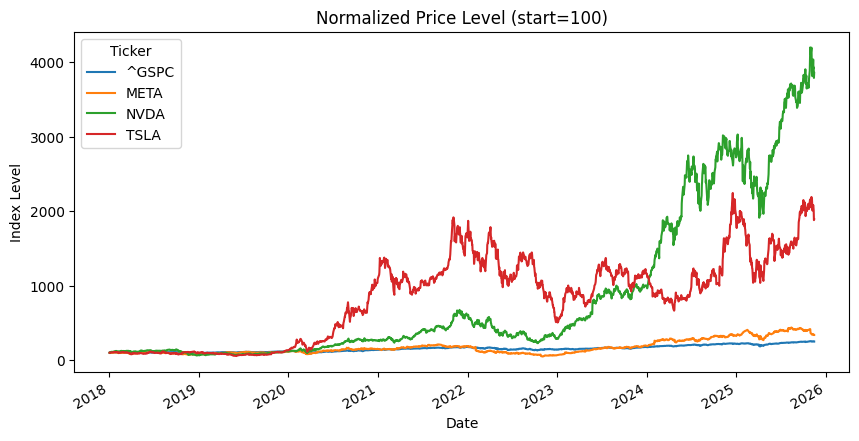

In [240]:
norm = closes_ffill / closes_ffill.iloc[0] * 100.0

ax = norm.plot(title="Normalized Price Level (start=100)")
ax.set_xlabel("Date")
ax.set_ylabel("Index Level")
plt.show()

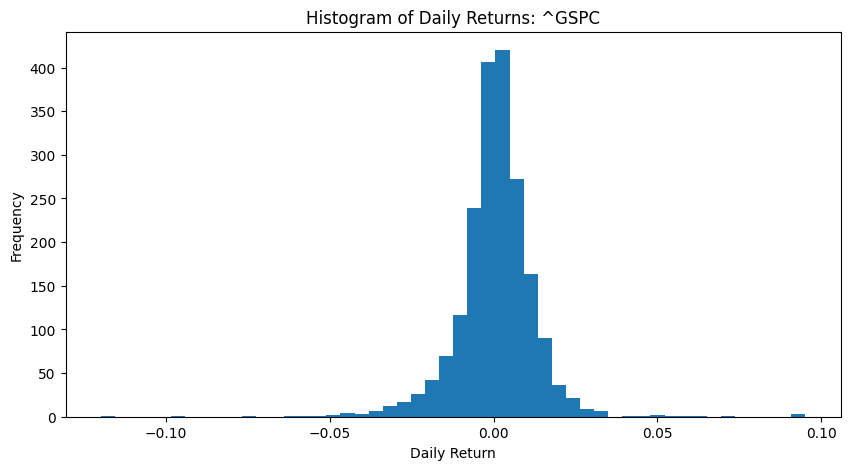

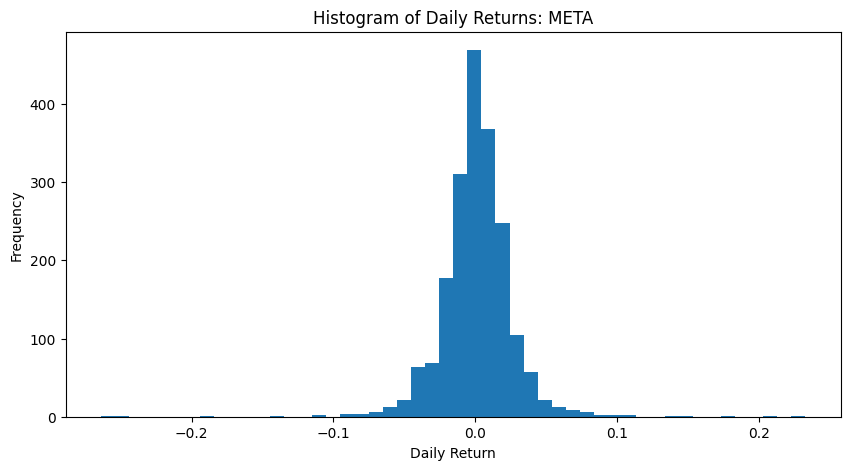

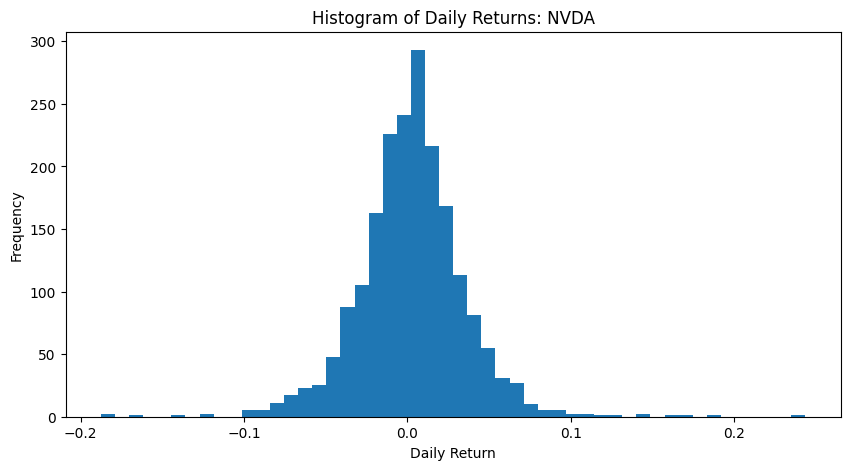

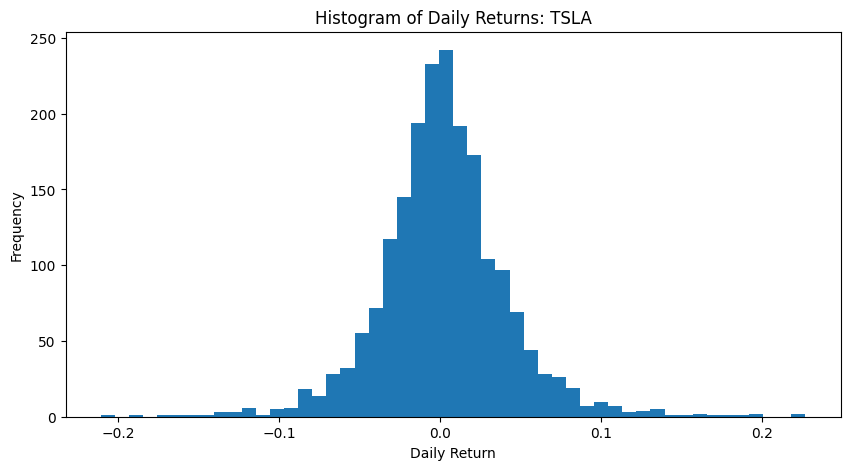

In [241]:
for col in simple_returns.columns:
    plt.figure()
    plt.hist(simple_returns[col].dropna(), bins=50)
    plt.title(f"Histogram of Daily Returns: {col}")
    plt.xlabel("Daily Return")
    plt.ylabel("Frequency")
    plt.show()

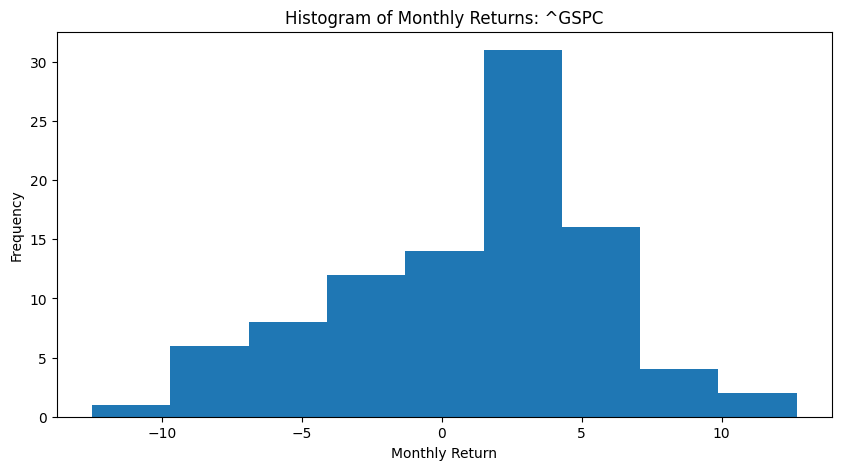

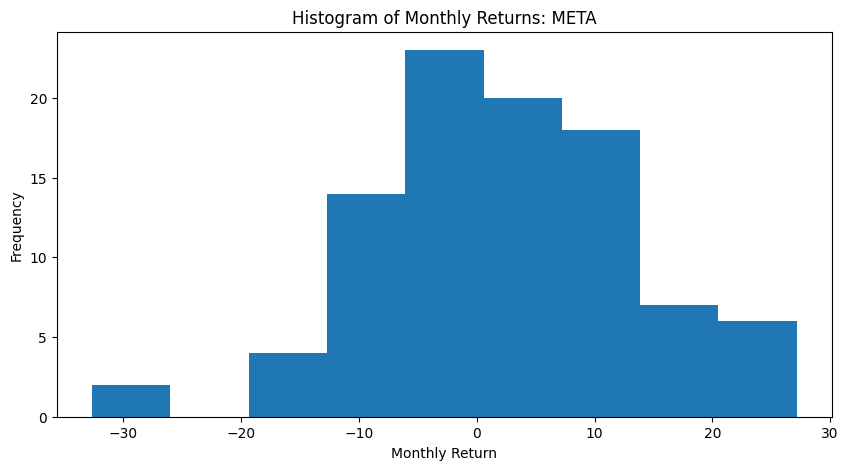

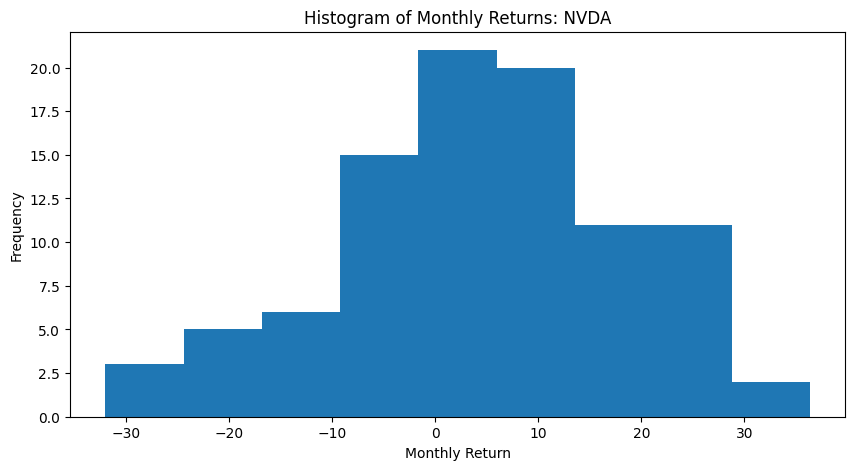

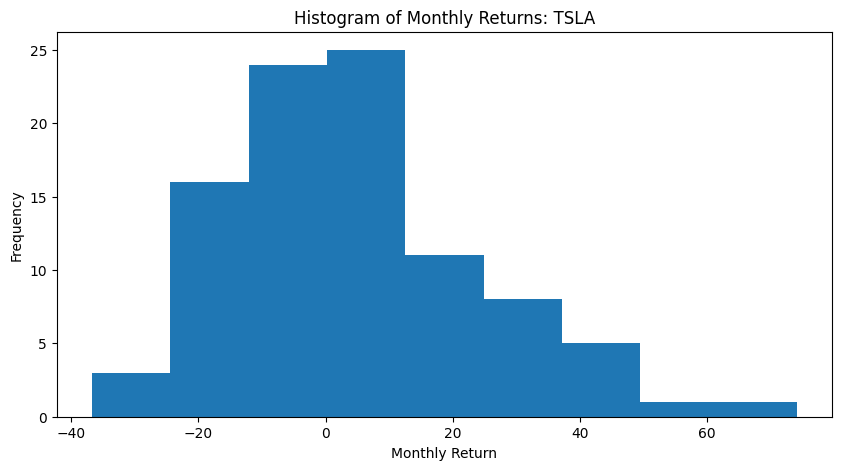

In [242]:
# Plot one histogram per ticker in a simple loop (one figure at a time)
for col in monthly_return.columns:
    plt.figure()
    n = len(monthly_return)
    plt.hist(monthly_return[col].dropna(), bins=int(np.sqrt(n)))
    plt.title(f"Histogram of Monthly Returns: {col}")
    plt.xlabel("Monthly Return")
    plt.ylabel("Frequency")
    plt.show()

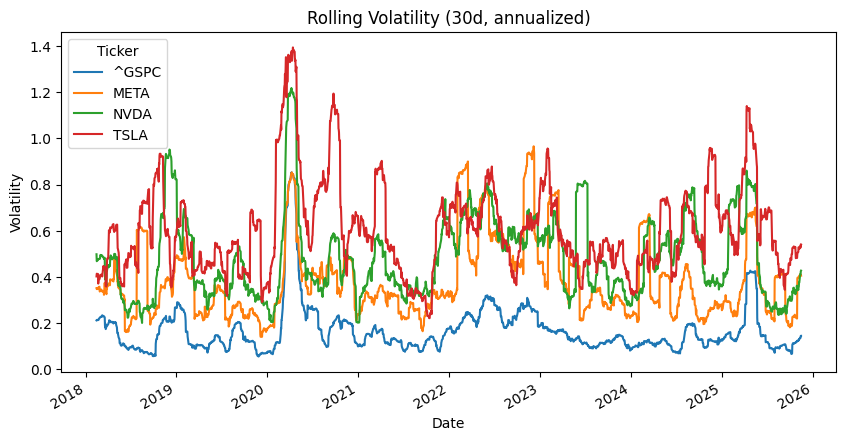

In [243]:
ax = rolling_vol.plot(title="Rolling Volatility (30d, annualized)")
ax.set_xlabel("Date")
ax.set_ylabel("Volatility")
plt.show()

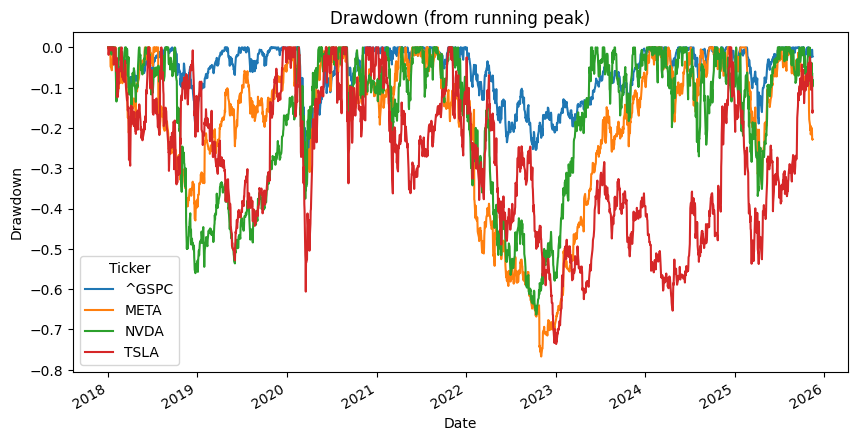

In [244]:
ax = drawdowns.plot(title="Drawdown (from running peak)")
ax.set_xlabel("Date")
ax.set_ylabel("Drawdown")
plt.show()

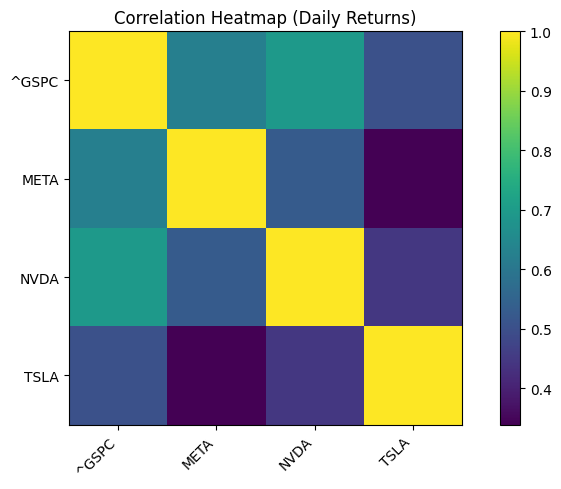

In [245]:
fig, ax = plt.subplots()
im = ax.imshow(corr_daily.values, interpolation='nearest')
ax.set_xticks(range(len(corr_daily.columns)))
ax.set_yticks(range(len(corr_daily.index)))
ax.set_xticklabels(corr_daily.columns, rotation=45, ha='right')
ax.set_yticklabels(corr_daily.index)
ax.set_title("Correlation Heatmap (Daily Returns)")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

In [246]:
def total_return_index(tkr):
    t = yf.Ticker(tkr)
    div = t.dividends
    c = closes[tkr].copy()
    c.index = c.index.tz_localize(None)
    div.index = div.index.tz_localize(None)
    div = div.reindex(c.index, method="ffill").fillna(0.0)
    tri = (c + div).div(c.shift(1)).fillna(1.0)
    return tri.cumprod()


tri = pd.concat({t: total_return_index(t) for t in ["TSLA","META","NVDA"]}, axis=1)
benchmark = total_return_index("^GSPC")

In [247]:
benchmark.head()

Date
2018-01-02    1.000000
2018-01-03    1.006399
2018-01-04    1.010453
2018-01-05    1.017561
2018-01-08    1.019252
dtype: float64

In [248]:
def cagr(series, freq=252):
    s = series.dropna()
    if s.empty: return np.nan
    total_ret = s.iloc[-1] / s.iloc[0] - 1
    years = (s.index[-1] - s.index[0]).days / 365.25
    return (1 + total_ret) ** (1/years) - 1 if years > 0 else np.nan

def max_drawdown(series):
    run_max = series.cummax()
    dd = series / run_max - 1.0
    return dd.min()

def daily_vol(returns):
    return returns.std(ddof=1)

def annualize_vol(returns):
    return returns.std(ddof=1)*np.sqrt(252)    

def var_cvar(returns, alpha=0.05):
    r = returns.dropna().sort_values()
    VaR = r.quantile(alpha)           # 5% quantile
    CVaR = r[r <= VaR].mean()         # average of worst 5%
    return VaR, CVaR

# Build a small table
rets_d = closes.pct_change()
tbl = {}
for t in ["TSLA","META","NVDA"]:
    tri_t = tri[t]
    tbl[t] = {
        "CAGR": cagr(tri_t),
        "Vol (daily)": daily_vol(rets_d[t]),
        "MaxDD": max_drawdown(tri_t),
        "VaR5% (daily)": var_cvar(rets_d[t], 0.05)[0],
        "CVaR5% (daily)": var_cvar(rets_d[t], 0.05)[1],
    }
pd.DataFrame(tbl).T


,CAGR,Vol (daily),MaxDD,VaR5% (daily),CVaR5% (daily)
TSLA,0.453265,0.040311,-0.736322,-0.058459,-0.087270
META,0.225444,0.026246,-0.767361,-0.037383,-0.058766
NVDA,0.738238,0.032466,-0.647396,-0.047452,-0.071011


In [249]:
benchmark_tkr = "^GSPC"
tickers = ["TSLA","META","NVDA"]
all_symbols = tickers + [benchmark_tkr]
data = yf.download(
    tickers=all_symbols,
    start="2018-01-01",
    auto_adjust=True,
    progress=False,
    group_by="ticker"
)

# 4) Extract Close as a clean DataFrame `closes`
if isinstance(data.columns, pd.MultiIndex):
    closes = data.xs("Close", level=1, axis=1)
else:
    # single ticker fallback
    closes = data[["Close"]].rename(columns={"Close": all_symbols[0]})

closes.index = pd.to_datetime(closes.index).tz_localize(None)
closes = closes.sort_index().ffill()

# 5) Ensure the benchmark column exists (fetch separately if missing)
if benchmark_tkr not in closes.columns:
    bench = yf.download(
        tickers=[benchmark_tkr],
        start=closes.index.min().strftime("%Y-%m-%d"),
        auto_adjust=True,
        progress=False
    )["Close"].rename(benchmark_tkr)
    bench.index = pd.to_datetime(bench.index).tz_localize(None)
    closes[benchmark_tkr] = bench.reindex(closes.index).ffill()

# 6) Compute daily returns
returns = closes.pct_change()



In [250]:
# 7) Rolling beta helper
def rolling_beta(asset_returns: pd.Series, market_returns: pd.Series, window: int = 252) -> pd.Series:
    cov = asset_returns.rolling(window).cov(market_returns)
    var = market_returns.rolling(window).var()
    return cov / var

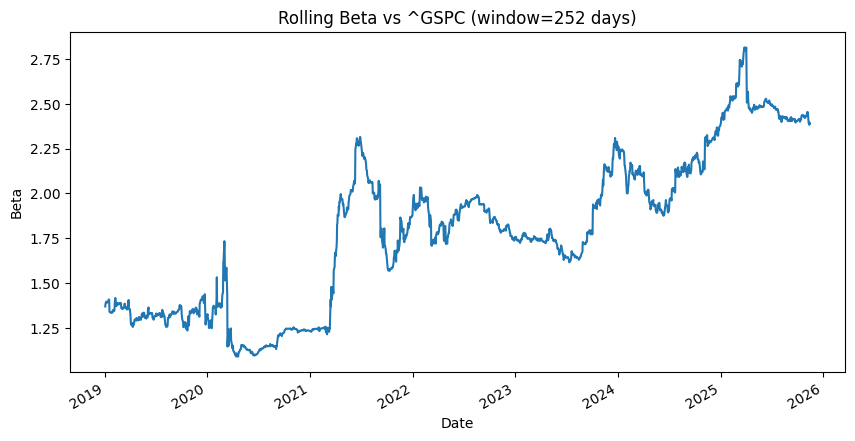

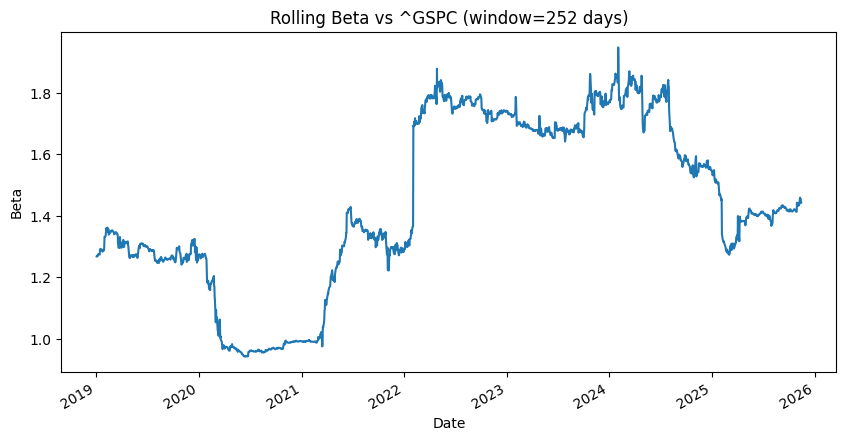

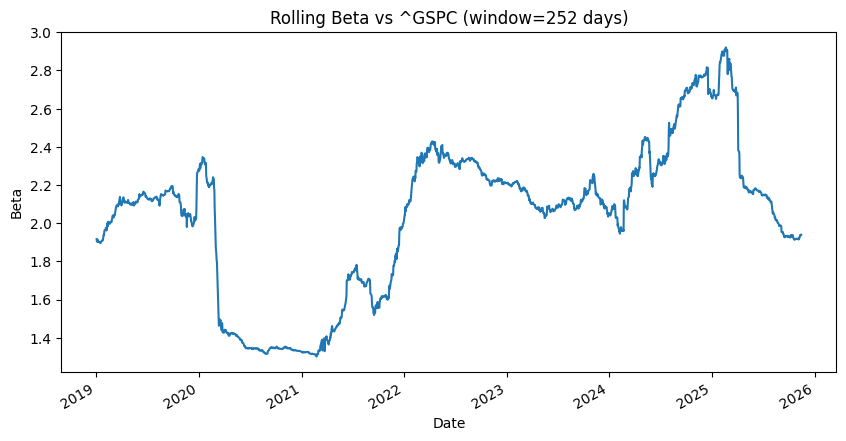

In [251]:
window = 252  # ~1 trading year
market_ret = returns[benchmark_tkr]

for t in tickers:
    if t not in returns.columns:
        print(f"Skipping {t}: not found in downloaded data.")
        continue
    beta_series = rolling_beta(returns[t], market_ret, window=window)
    ax = beta_series.plot(title=f"Rolling Beta vs {benchmark_tkr} (window={window} days)")
    ax.set_xlabel("Date")
    ax.set_ylabel("Beta")
    plt.show()

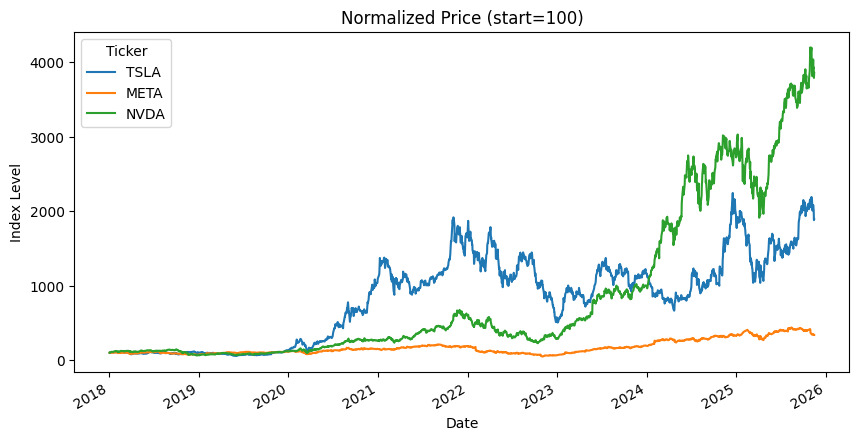

In [252]:
# 9) Optional: normalized price comparison (start=100)
norm = closes[tickers] / closes[tickers].iloc[0] * 100.0
ax = norm.plot(title="Normalized Price (start=100)")
ax.set_xlabel("Date")
ax.set_ylabel("Index Level")
plt.show()